# Lab 8: Profiling and optimization analysis

Baseline profiling of `lab1.py` (mosaic reconstruction) and before/after comparison with the optimized `lab8.py`.

**Baseline model:** the `lab1.py` mosaic pipeline with **`find_best_tile_looped()`** choosing the tiles (defined once, in the *Baseline model* section). Parts 1, 1b and 5 all time this same baseline.

**How to use:** keep this notebook in the project folder, next to `lab1.py`, `lab8.py`, `tiles/` and `img/`. Run the cells top to bottom (*Run All* works). Everything is saved to `perf_results/`.

| Part | What it does | Files saved in `perf_results/` |
|---|---|---|
| 1 | Baseline total time, mean of N runs, all 9 configs | `baseline_timing.csv/.txt`, `baseline_scaling.png` |
| 1b | Baseline per-stage breakdown | `baseline_breakdown.csv/.txt/.png` |
| 2 | Function-level profile (cProfile) | `cprofile_<size>px_grid<n>.txt/.prof` |
| 3 | Line-by-line profile (line_profiler) | `line_profile_<size>px_grid<n>.txt` |
| 4 | Updated code with optimizations (`lab8.py`) | – |
| 5 | Before/after comparison: timing, speedups, correctness | `comparison_*`, `lab8_stage_speedups.*`, `lab8_resize_cache.txt`, `report_tables.md`, `cprofile_lab8_*` |

## Setup

In [25]:
import cProfile
import csv
import importlib
import io
import os
import pstats
import re
import statistics
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [26]:
PROJECT_DIR = Path.cwd()
# PROJECT_DIR = Path("/path/to/your/project")

if not (PROJECT_DIR / "lab1.py").exists():
    raise FileNotFoundError(f"lab1.py not found in {PROJECT_DIR}; set PROJECT_DIR above")

# lab1.py loads tiles/ with a relative path at import time, so chdir first.
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Importing lab1 runs its Streamlit calls in "bare mode"; warnings about a missing
# ScriptRunContext are expected and harmless. reload() picks up edits to lab1.py
# without restarting the kernel.
import lab1
lab1 = importlib.reload(lab1)

RESULTS_DIR = PROJECT_DIR / "perf_results"
RESULTS_DIR.mkdir(exist_ok=True)

print(f"Project folder: {PROJECT_DIR}")
print(f"Results folder: {RESULTS_DIR}")
print(f"Tile library:   {len(lab1.tile_images_pil)} tiles")

2026-11-26 14:33:45.830 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 14:33:45.831 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 14:33:45.831 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 14:33:45.831 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 14:33:45.833 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 14:33:45.834 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 14:33:45.834 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 14:33:45.835 No runtime found, using MemoryCacheStorageManager
2026-11-26 14:33:45.938 Thread 'MainThread':

Project folder: /Users/megukanzawa/Downloads/CS/Northeastern/CS5130/Labs/Week2
Results folder: /Users/megukanzawa/Downloads/CS/Northeastern/CS5130/Labs/Week2/perf_results
Tile library:   14 tiles


## Configuration

In [27]:
IMAGE_SIZES = [256, 512, 1024]
# "Grid size" = number of tiles per side, so tile_size = image_size // grid_size.
# e.g. 256x256 with a 16x16 grid -> 16 px tiles; 1024x1024 with 64x64 -> 16 px tiles.
GRID_SIZES = [16, 32, 64]
REQUIRED_CONFIGS = [(256, 16), (512, 32), (1024, 64)]

RUNS = 3                    # timed runs per configuration
WARMUP = 1                  # untimed warm-up runs per configuration
CPROFILE_TOP = 20           # rows to show in each cProfile table
LINE_PROFILE_CONFIG = (1024, 64)   # (image size, grid size) for line_profiler

TEST_IMAGE_DIR = PROJECT_DIR / "test_images"
SOURCE_IMAGE = PROJECT_DIR / "img" / "cake4.png"

# Functions profiled line by line in Part 3.
LINE_PROFILE_TARGETS = [
    lab1.mosaic_construction,
    lab1.find_best_tile_looped,
    lab1.calculate_ssim,
    lab1.calculate_mse,
]

## Helpers

In [28]:
def load_test_images():
    """Same images the test suite uses: test_images/test_<n>x<n>.png, made from img/cake4.png."""
    TEST_IMAGE_DIR.mkdir(exist_ok=True)
    images = {}
    for size in IMAGE_SIZES:
        path = TEST_IMAGE_DIR / f"test_{size}x{size}.png"
        if not path.exists():
            if not SOURCE_IMAGE.exists():
                raise FileNotFoundError(f"{SOURCE_IMAGE} not found and {path} does not exist")
            (Image.open(SOURCE_IMAGE).convert("RGB")
                  .resize((size, size), Image.Resampling.LANCZOS)
                  .save(path))
        images[size] = Image.open(path).convert("RGB")
    return images


def tile_size_for(image_size, grid_size):
    return image_size // grid_size


def grab(pattern, text):
    m = re.search(pattern, text)
    return float(m.group(1)) if m else float("nan")


def banner(title):
    line = "=" * 78
    return f"\n{line}\n{title}\n{line}"


def save_text(name, text):
    path = RESULTS_DIR / name
    path.write_text(text)
    return path


def save_csv(name, rows):
    path = RESULTS_DIR / name
    with open(path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)
    return path


def save_and_show(fig, name):
    """Save a figure to perf_results/ and also display it in the notebook."""
    path = RESULTS_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path}")
    plt.show()

In [29]:
images = load_test_images()
for size, img in images.items():
    print(f"{size}x{size}: {img.size}")

256x256: (256, 256)
512x512: (512, 512)
1024x1024: (1024, 1024)


## Baseline model

The baseline is `lab1.mosaic_construction` with the looped search, `find_best_tile_looped()`, choosing the tiles. `baseline_mosaic()` below copies each stage of `lab1.mosaic_construction` line for line, using `lab1`'s own helper functions and tile library, and times every stage.

The one difference from `lab1.py` as written: `lab1` builds its mosaic from the vectorized `find_best_tile()` and runs the looped search only to time it. Here the looped search chooses the tiles and the vectorized search is not run. Both searches pick the same tiles, so the mosaic is identical; Part 1b checks this for every configuration.

In [30]:
# Every stage of the baseline, in order: (key, label for tables/plots).
STAGES = [
    ("to_array",  "Convert to array"),
    ("crop_grid", "Crop + red grid"),
    ("cell_avg",  "Cell averages"),
    ("looped",    "Looped tile search"),
    ("resize",    "Resize tiles"),
    ("paste",     "Paste tiles"),
    ("to_pil",    "Convert to PIL"),
    ("mse",       "MSE"),
    ("ssim",      "SSIM"),
]


def baseline_mosaic(image, tile_size, compute_metrics=True):
    """Baseline model: lab1's pipeline with find_best_tile_looped() choosing the tiles.

    Returns (mosaic array, tile indices, {stage key: ms}). With compute_metrics=False,
    MSE and SSIM are skipped (their stages are recorded as 0 ms).
    """
    clock = time.time
    t = {}

    s = clock()
    img = np.array(image.convert("RGB"))
    t["to_array"] = clock() - s

    s = clock()
    th = tw = int(tile_size)
    h, w, ch = img.shape
    g = min(h // th, w // tw)
    valid = g * th
    sh, sw = (h - valid) // 2, (w - valid) // 2
    cropped = img[sh:sh + valid, sw:sw + valid, :]
    segmented = cropped.copy()
    for r in range(1, g):
        segmented[r * th, :, :] = [255, 0, 0]
    for c in range(1, g):
        segmented[:, c * tw, :] = [255, 0, 0]
    t["crop_grid"] = clock() - s

    s = clock()
    blocked = cropped.reshape(g, th, g, tw, ch).transpose(0, 2, 1, 3, 4)
    cell_avg = np.mean(blocked, axis=(2, 3))
    t["cell_avg"] = clock() - s

    s = clock()
    best = lab1.find_best_tile_looped(cell_avg)      # the baseline tile search
    t["looped"] = clock() - s

    s = clock()
    resized = [np.array(tile.resize((tw, th), Image.Resampling.BILINEAR))
               for tile in lab1.tile_images_pil]
    t["resize"] = clock() - s

    s = clock()
    canvas = np.zeros((valid, valid, 3), dtype=np.uint8)
    for r in range(g):
        for c in range(g):
            canvas[r * th:(r + 1) * th, c * tw:(c + 1) * tw, :] = resized[best[r, c]]
    t["paste"] = clock() - s

    s = clock()
    Image.fromarray(canvas)
    Image.fromarray(cropped)
    Image.fromarray(segmented)
    t["to_pil"] = clock() - s

    t["mse"] = t["ssim"] = 0.0
    if compute_metrics:
        s = clock()
        lab1.calculate_mse(cropped, canvas)
        t["mse"] = clock() - s

        s = clock()
        lab1.calculate_ssim(cropped, canvas)
        t["ssim"] = clock() - s

    return canvas, best, {k: v * 1000 for k, v in t.items()}

## Part 1: Baseline timing

Times the whole baseline model (`baseline_mosaic`) with `time.time()`. Each of the 9 configurations is run once as a warm-up, then `RUNS` timed runs. For each configuration the table shows:

- the mean and standard deviation of the total time;
- a breakdown into the looped tile search and everything else;
- a `*` on the required configurations.

In [31]:
def run_timing(images, runs, warmup=1):
    """Time the whole baseline model for every image/grid combination."""
    rows, lines = [], []
    lines.append(banner(f"PART 1: BASELINE TIMING (mean of {runs} runs, {warmup} warm-up run discarded)"))
    header = (f"{'Image':>9} {'Grid':>7} {'Tile px':>7} {'Mean ms':>10} {'Std ms':>8} "
              f"{'Loop ms':>10} {'Other ms':>9} {'Loop %':>7}  Req")
    lines += [header, "-" * len(header)]
    print("\n".join(lines))

    for size in IMAGE_SIZES:
        for grid in GRID_SIZES:
            tile = tile_size_for(size, grid)
            img = images[size]

            for _ in range(warmup):
                baseline_mosaic(img, tile)

            totals, loops = [], []
            for _ in range(runs):
                t0 = time.time()
                _, _, stage_ms = baseline_mosaic(img, tile)
                totals.append((time.time() - t0) * 1000)
                loops.append(stage_ms["looped"])

            mean_total = statistics.mean(totals)
            std_total = statistics.stdev(totals) if runs > 1 else 0.0
            mean_loop = statistics.mean(loops)
            other = mean_total - mean_loop   # cropping, cell averages, resizing, pasting, metrics
            required = (size, grid) in REQUIRED_CONFIGS

            rows.append({
                "image_size": size, "grid_size": grid, "tile_px": tile,
                "cells": grid * grid, "runs": runs,
                "mean_total_ms": round(mean_total, 3), "std_total_ms": round(std_total, 3),
                "mean_looped_ms": round(mean_loop, 3), "mean_other_ms": round(other, 3),
                "looped_pct": round(100 * mean_loop / mean_total, 1),
                "required": required,
                "all_runs_ms": " ".join(f"{t:.2f}" for t in totals),
            })
            line = (f"{size:>4}x{size:<4} {f'{grid}x{grid}':>7} {tile:>7} {mean_total:>10.2f} "
                    f"{std_total:>8.2f} {mean_loop:>10.2f} {other:>9.2f} "
                    f"{100 * mean_loop / mean_total:>6.1f}%  {'*' if required else ''}")
            lines.append(line)
            print(line)   # print as we go so progress is visible

    footer = "\n* = required configuration.  Other = total - looped search."
    lines.append(footer)
    print(footer)

    print(f"Saved {save_csv('baseline_timing.csv', rows)}")
    print(f"Saved {save_text('baseline_timing.txt', chr(10).join(lines))}")
    plot_scaling(rows)
    return rows


def plot_scaling(rows):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    for size in IMAGE_SIZES:
        r = [row for row in rows if row["image_size"] == size]
        grids = [row["grid_size"] for row in r]
        ax1.errorbar(grids, [row["mean_total_ms"] for row in r],
                     yerr=[row["std_total_ms"] for row in r],
                     marker="o", capsize=3, label=f"{size}x{size} image")
    ax1.set_title("Total mosaic generation time (baseline)")
    ax1.set_xlabel("Grid size (tiles per side)")
    ax1.set_ylabel("Mean time (ms)")
    ax1.set_xticks(GRID_SIZES, [f"{g}x{g}" for g in GRID_SIZES])
    ax1.set_yscale("log")
    ax1.grid(True, which="both", alpha=0.3)
    ax1.legend()

    # Stacked breakdown for the three required configurations.
    req = [row for row in rows if row["required"]]
    labels = [f"{row['image_size']}px\n{row['grid_size']}x{row['grid_size']}" for row in req]
    loop = [row["mean_looped_ms"] for row in req]
    other = [row["mean_other_ms"] for row in req]
    ax2.bar(labels, loop, label="Looped tile search")
    ax2.bar(labels, other, bottom=loop, label="Everything else")
    ax2.set_title("Where the time goes (required configs)")
    ax2.set_ylabel("Mean time (ms)")
    ax2.legend()

    fig.tight_layout()
    save_and_show(fig, "baseline_scaling.png")


PART 1: BASELINE TIMING (mean of 3 runs, 1 warm-up run discarded)
    Image    Grid Tile px    Mean ms   Std ms    Loop ms  Other ms  Loop %  Req
-------------------------------------------------------------------------------
 256x256    16x16      16      50.38     9.89       8.33     42.05   16.5%  *
 256x256    32x32       8      68.15     5.01      31.68     36.48   46.5%  
 256x256    64x64       4     162.97     1.37     125.22     37.76   76.8%  
 512x512    16x16      32     109.29     5.20       8.00    101.30    7.3%  
 512x512    32x32      16     138.01     7.35      32.61    105.40   23.6%  *
 512x512    64x64       8     235.58     7.87     126.08    109.51   53.5%  
1024x1024   16x16      64     542.02    12.00       7.89    534.13    1.5%  
1024x1024   32x32      32     585.55    46.95      32.47    553.07    5.5%  
1024x1024   64x64      16     639.08     2.53     124.12    514.97   19.4%  *

* = required configuration.  Other = total - looped search.
Saved /Users/meg

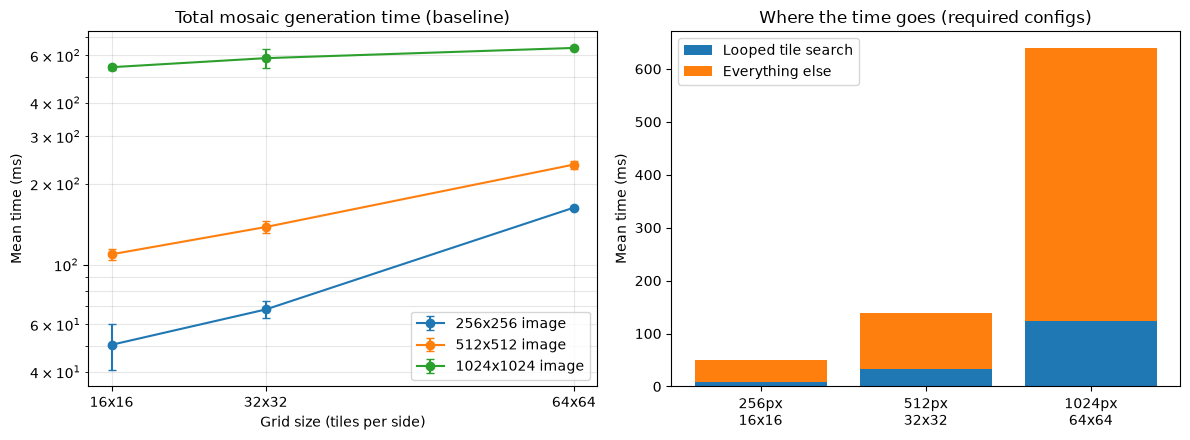

In [32]:
timing_rows = run_timing(images, RUNS, WARMUP)

## Part 1b: Per-stage breakdown

Mean time of every stage of the baseline model, so “everything else” becomes named stages. For every configuration it also checks that the baseline model builds exactly the same mosaic as `lab1.mosaic_construction`, and stops with an error if not.

In [33]:
def run_breakdown(images, runs, warmup=1):
    """Mean time of every baseline stage, for every image/grid combination."""
    lines = [banner(f"PART 1b: PER-STAGE BREAKDOWN (mean of {runs} runs, times in ms)")]
    short = ["Array", "Crop", "CellAvg", "Loop", "Resize", "Paste", "ToPIL", "MSE", "SSIM"]
    header = (f"{'Image':>9} {'Grid':>7} {'Total':>8} | "
              + " ".join(f"{name:>7}" for name in short) + " | Largest stage")
    lines += [header, "-" * len(header)]
    print("\n".join(lines))

    rows = []
    for size in IMAGE_SIZES:
        for grid in GRID_SIZES:
            tile = tile_size_for(size, grid)
            img = images[size]

            for _ in range(warmup):
                baseline_mosaic(img, tile)
            stage_runs = []
            for _ in range(runs):
                canvas, _, stage_ms = baseline_mosaic(img, tile)
                stage_runs.append(stage_ms)

            # Correctness check: the baseline model must build exactly lab1's mosaic.
            _, _, lab1_mosaic, _ = lab1.mosaic_construction(img, tile)
            if not np.array_equal(canvas, np.array(lab1_mosaic)):
                raise RuntimeError(f"baseline model differs from lab1 at {size}px / {grid}x{grid}")

            means = {k: statistics.mean(run[k] for run in stage_runs) for k, _ in STAGES}
            total = sum(means.values())
            top_key, top_label = max(STAGES, key=lambda st: means[st[0]])

            row = {"image_size": size, "grid_size": grid, "tile_px": tile, "runs": runs,
                   "total_ms": round(total, 3)}
            for key, _ in STAGES:
                row[f"{key}_ms"] = round(means[key], 3)
            for key, _ in STAGES:
                row[f"{key}_pct"] = round(100 * means[key] / total, 1)
            row["required"] = (size, grid) in REQUIRED_CONFIGS
            rows.append(row)

            line = (f"{size:>4}x{size:<4} {f'{grid}x{grid}':>7} {total:>8.2f} | "
                    + " ".join(f"{means[k]:>7.2f}" for k, _ in STAGES)
                    + f" | {top_label} ({100 * means[top_key] / total:.0f}%)"
                    + ("  *" if row["required"] else ""))
            lines.append(line)
            print(line)

    footer = ("\nTotal = sum of the stage means.  * = required.\n"
              "The baseline model's mosaic matched lab1.mosaic_construction exactly for every configuration.")
    lines.append(footer)
    print(footer)

    print(f"Saved {save_csv('baseline_breakdown.csv', rows)}")
    print(f"Saved {save_text('baseline_breakdown.txt', chr(10).join(lines))}")
    plot_breakdown(rows)
    return rows


def plot_breakdown(rows):
    labels = [f"{r['image_size']}px\n{r['grid_size']}x{r['grid_size']}"
              + ("*" if r["required"] else "") for r in rows]
    colors = plt.get_cmap("tab10").colors
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

    for ax, suffix, ylabel, title in (
        (ax1, "_ms", "Mean time (ms)", "Time per stage (baseline)"),
        (ax2, "_pct", "Share of total (%)", "Share of total time per stage (baseline)"),
    ):
        bottom = [0.0] * len(rows)
        for (key, label), color in zip(STAGES, colors):
            values = [r[key + suffix] for r in rows]
            ax.bar(labels, values, bottom=bottom, label=label, color=color)
            bottom = [b + v for b, v in zip(bottom, values)]
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", labelsize=8)

    ax2.set_ylim(0, 100)
    ax2.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
    fig.text(0.5, 0.01, "* = required configuration", ha="center", fontsize=9)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    save_and_show(fig, "baseline_breakdown.png")


PART 1b: PER-STAGE BREAKDOWN (mean of 3 runs, times in ms)
    Image    Grid    Total |   Array    Crop CellAvg    Loop  Resize   Paste   ToPIL     MSE    SSIM | Largest stage
--------------------------------------------------------------------------------------------------------------------
 256x256    16x16    43.78 |    0.09    0.07    1.00    8.00   20.22    0.19    0.11    0.27   13.83 | Resize tiles (46%)  *
 256x256    32x32    64.85 |    0.09    0.13    0.96   31.29   18.12    0.54    0.10    0.23   13.39 | Looped tile search (48%)
 256x256    64x64   160.79 |    0.09    0.26    1.16  126.53   16.80    2.11    0.12    0.26   13.47 | Looped tile search (79%)
 512x512    16x16   113.50 |    0.19    0.12    3.33    7.70   19.04    0.24    0.25    0.78   81.84 | SSIM (72%)
 512x512    32x32   130.75 |    0.21    0.24    4.36   31.42   19.37    0.75    0.26    0.80   73.35 | SSIM (56%)  *
 512x512    64x64   242.50 |    0.21    0.46    3.83  124.20   19.27    2.43    0.27    0.84  

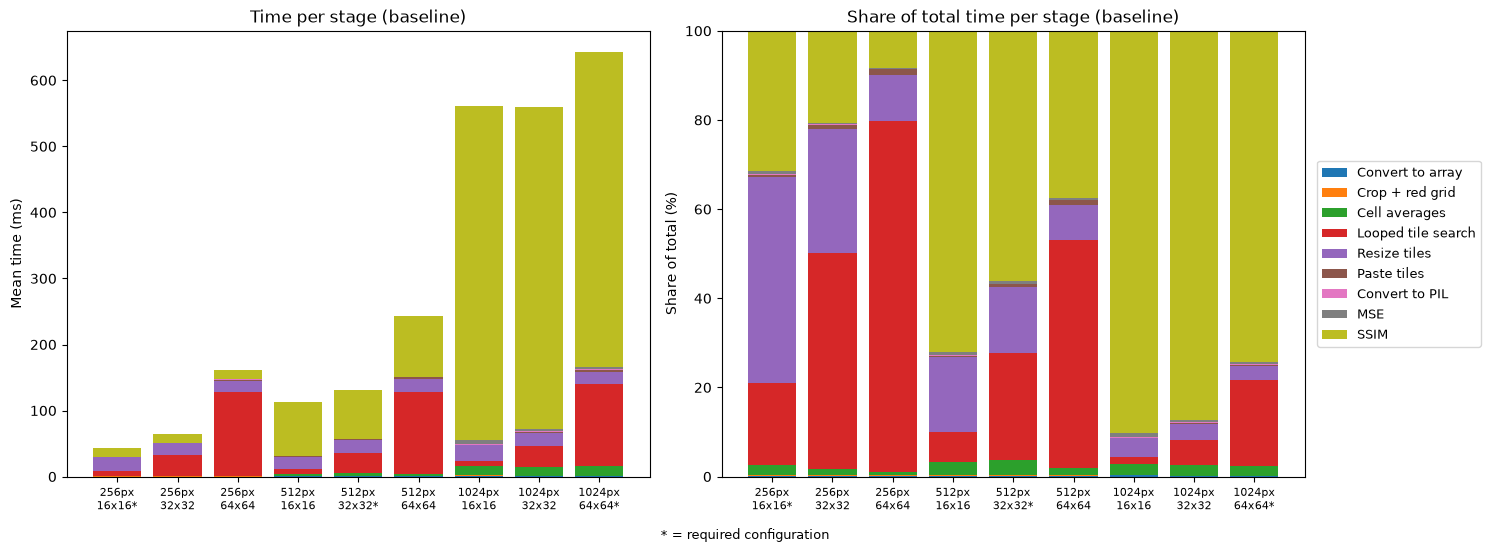

In [34]:
breakdown_rows = run_breakdown(images, RUNS, WARMUP)

## Part 2: cProfile (function level)

Profiles `lab1.mosaic_construction` as written for the three required configurations and prints the top functions sorted three ways: cumulative time, internal time, and call count. `lab1.mosaic_construction` runs both the vectorized and the looped search, so the baseline's looped search shows up here. The `.prof` files can be explored visually with `snakeviz perf_results/<file>.prof`.

In [35]:
def run_cprofile(images, configs, top):
    print(banner("PART 2: cProfile (function level)"))
    for size, grid in configs:
        tile = tile_size_for(size, grid)
        profiler = cProfile.Profile()
        profiler.runcall(lab1.mosaic_construction, images[size], tile)

        stem = f"cprofile_{size}px_grid{grid}"
        profiler.dump_stats(RESULTS_DIR / f"{stem}.prof")   # open with: snakeviz <file>

        buf = io.StringIO()
        stats = pstats.Stats(profiler, stream=buf).strip_dirs()
        buf.write(f"\n### {size}x{size} image, {grid}x{grid} grid ({tile} px tiles)\n")
        buf.write("\n--- sorted by cumulative time (time in function + everything it calls) ---\n")
        stats.sort_stats("cumulative").print_stats(top)
        buf.write("\n--- sorted by internal time (time in the function body itself) ---\n")
        stats.sort_stats("tottime").print_stats(top)
        buf.write("\n--- sorted by call count (look for things called far more than expected) ---\n")
        stats.sort_stats("ncalls").print_stats(top)

        text = buf.getvalue()
        print(text)
        print(f"Saved {save_text(stem + '.txt', text)} and {stem}.prof")

In [36]:
run_cprofile(images, REQUIRED_CONFIGS, CPROFILE_TOP)


PART 2: cProfile (function level)

### 256x256 image, 16x16 grid (16 px tiles)

--- sorted by cumulative time (time in function + everything it calls) ---
         24027 function calls (24022 primitive calls) in 0.048 seconds

   Ordered by: cumulative time
   List reduced from 207 to 20 due to restriction <20>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.048    0.048 lab1.py:118(mosaic_construction)
       14    0.000    0.000    0.020    0.001 Image.py:2329(resize)
       14    0.019    0.001    0.019    0.001 {method 'resize' of 'ImagingCore' objects}
        1    0.000    0.000    0.014    0.014 lab1.py:56(calculate_ssim)
      4/1    0.001    0.000    0.014    0.014 _structural_similarity.py:15(structural_similarity)
       15    0.000    0.000    0.013    0.001 _filters.py:1552(uniform_filter)
       30    0.000    0.000    0.012    0.000 _filters.py:1501(uniform_filter1d)
       30    0.012    0.000    0.012    0.000 

## Part 3: line_profiler (line level)

Profiles the slowest functions line by line for `LINE_PROFILE_CONFIG` (times in ms). Change that setting in the Configuration cell to profile another configuration. The looped search runs much slower under line_profiler, so this cell can take a while.

In [37]:
def run_line_profiler(images, size, grid):
    try:
        from line_profiler import LineProfiler
    except ImportError:
        print("line_profiler is not installed: run  %pip install line_profiler  in a cell, then re-run this one")
        return

    tile = tile_size_for(size, grid)
    print(banner(f"PART 3: line_profiler, {size}x{size} image, {grid}x{grid} grid ({tile} px tiles)"))

    lp = LineProfiler(*LINE_PROFILE_TARGETS)
    lp.runcall(lab1.mosaic_construction, images[size], tile)

    buf = io.StringIO()
    lp.print_stats(stream=buf, output_unit=1e-3)   # times in ms
    text = buf.getvalue()
    print(text)
    print(f"Saved {save_text(f'line_profile_{size}px_grid{grid}.txt', text)}")

In [38]:
run_line_profiler(images, *LINE_PROFILE_CONFIG)


PART 3: line_profiler, 1024x1024 image, 64x64 grid (16 px tiles)
Timer unit: 0.001 s

Total time: 0.931202 s
File: /Users/megukanzawa/Downloads/CS/Northeastern/CS5130/Labs/Week2/lab1.py
Function: mosaic_construction at line 118

Line #      Hits         Time  Per Hit   % Time  Line Contents
   118                                           def mosaic_construction(image, tile_size):
   119                                               """
   120                                               Constructs a mosaic visualization from an input image and tile size.
   121                                               
   122                                               Parameters:
   123                                               - image: PIL Image or numpy array supplied by Gradio
   124                                               - tile_size: int, width and height of each tile in pixels
   125                                               """
   126                                     

## Part 4: Updated code with optimizations (`lab8.py`)

`lab8.py` is the optimized version, with the same inputs, outputs and Streamlit app as `lab1.py`. Each optimization targets a bottleneck found in Parts 1–3:

| # | Bottleneck in the baseline | Optimization in `lab8.py` | Function |
|---|---|---|---|
| 1 | Grid drawn with loops; tiles pasted with a double loop over cells | Slice assignments; one fancy-indexing step | `draw_grid`, `assemble_mosaic` |
| 1 | Cell averages over a transposed 5-D array | Exact `uint32` sums over contiguous rows | `cell_average_colors` |
| 2 | `find_best_tile_looped`: rows × cols × N Python iterations | Tile colors and a k-d tree computed once; one vectorized query | `TileLibrary.__init__`, `TileLibrary.nearest` |
| 3 | `st.cache_data` hands back a fresh copy of the tiles on every rerun | Tiles loaded once and shared (`st.cache_resource`) | `get_tile_library` |
| 4 | Every tile resized on every call | Each tile size resized once, then cached | `TileLibrary.resized` |
| 5 | MSE with two `astype` copies; metrics always computed | One pass + BLAS dot product; metrics optional | `calculate_mse`, `build_mosaic` |

### Before and after: key code changes

**Tile search** (baseline: `find_best_tile_looped`, rows × cols × N iterations)

```python
# before                                            # after (lab8)
for r in range(rows):                               self.tree = cKDTree(self.avg_colors)   # once, at startup
    for c in range(cols):                           ...
        for idx, tile_rgb in enumerate(tile_avg_colors):
            dist = np.sum((cell_rgb - tile_rgb) ** 2)   _, idx = self.tree.query(colors.reshape(-1, 3))
            ...
```

**Pasting tiles** (double loop over cells → one indexing step)

```python
# before
for r in range(grid_dim):
    for c in range(grid_dim):
        mosaic_canvas[r*th:(r+1)*th, c*tw:(c+1)*tw, :] = resized_tiles[best_indices[r, c]]
# after
resized_tiles[tile_indices].transpose(0, 2, 1, 3, 4).reshape(g * s, g * s, 3)
```

**Red grid** (loops → slicing)

```python
# before
for r in range(1, grid_dim):
    img_segmented[r * tile_h1, :, :] = [255, 0, 0]
# after
segmented[tile_size::tile_size, :] = GRID_COLOR
```

**Resizing** (every call → once per tile size)

```python
# before: in every call
resized_tiles = [np.array(t.resize((tw, th), Image.Resampling.BILINEAR)) for t in tile_images_pil]
# after: cached
tiles = self._resized.get(tile_size)
if tiles is None:
    tiles = np.stack([...]); self._resized[tile_size] = tiles
```

In [39]:
import inspect

import lab8
lab8 = importlib.reload(lab8)

# The comparison is only fair if both versions see the same tiles in the same order.
assert len(lab8.TILES) == len(lab1.tile_images_pil)
assert np.array_equal(lab8.tile_avg_colors, lab1.tile_avg_colors), "tile libraries differ"
print(f"lab8 loaded with the same {len(lab8.TILES)} tiles as lab1")

try:
    from IPython.display import Markdown, display
    def show_source(fn):
        display(Markdown(f"```python\n{inspect.getsource(fn)}```"))
except ImportError:
    def show_source(fn):
        print(inspect.getsource(fn))

# The optimized functions, shown straight from lab8.py so this section always matches the code.
for fn in (lab8.TileLibrary.__init__, lab8.TileLibrary.resized, lab8.TileLibrary.nearest,
           lab8.draw_grid, lab8.cell_average_colors, lab8.assemble_mosaic,
           lab8.calculate_mse, lab8.build_mosaic):
    show_source(fn)

lab8 loaded with the same 14 tiles as lab1


```python
    def __init__(self, folder=TILE_FOLDER):
        # Same file order as lab1, so tile indices can be compared directly.
        paths = glob.glob(f"{folder}/*.png") + glob.glob(f"{folder}/*.jpg")

        self.images = []
        colors = []
        for p in paths:                       # runs once, at startup
            try:
                img = Image.open(p).convert("RGB")
            except Exception as e:
                print(f"Error loading tile {p}: {e}")
                continue
            self.images.append(img)
            colors.append(np.asarray(img).mean(axis=(0, 1)))

        if not self.images:
            raise FileNotFoundError(f"No .png or .jpg tiles found in '{folder}/'")

        self.avg_colors = np.array(colors)        # (N, 3) float64
        self.tree = cKDTree(self.avg_colors)      # nearest-neighbor index over tile colors
        self._resized = {}                        # tile_size -> (N, s, s, 3) uint8
```

```python
    def resized(self, tile_size):
        """All tiles at tile_size x tile_size as one (N, s, s, 3) array, resized only once."""
        tiles = self._resized.get(tile_size)
        if tiles is None:
            tiles = np.stack([np.asarray(t.resize((tile_size, tile_size), RESAMPLE))
                              for t in self.images])
            self._resized[tile_size] = tiles
        return tiles
```

```python
    def nearest(self, colors):
        """Index of the closest tile (Euclidean RGB distance) for each color in an (..., 3) array."""
        _, idx = self.tree.query(colors.reshape(-1, 3))
        return idx.reshape(colors.shape[:-1])
```

```python
def draw_grid(cropped, tile_size):
    """Copy of the image with a red line every tile_size pixels (two slice assignments)."""
    segmented = cropped.copy()
    segmented[tile_size::tile_size, :] = GRID_COLOR
    segmented[:, tile_size::tile_size] = GRID_COLOR
    return segmented
```

```python
def cell_average_colors(cropped, grid_dim, tile_size):
    """Average color of every grid cell, shape (grid_dim, grid_dim, 3).

    The reshape splits each axis into (cell, pixel within cell). Summing over the
    pixel rows first adds whole contiguous rows at once, which is much faster than
    averaging a transposed array. uint32 sums are exact (no overflow below 4096 px
    tiles), so the result is bit-identical to lab1's np.mean.
    """
    blocks = cropped.reshape(grid_dim, tile_size, grid_dim, tile_size, 3)
    sums = blocks.sum(axis=1, dtype=np.uint32).sum(axis=2)
    return sums / (tile_size * tile_size)
```

```python
def assemble_mosaic(resized_tiles, tile_indices):
    """Place the chosen tile in every cell with one fancy-indexing step.

    resized_tiles[tile_indices] has shape (grid, grid, s, s, 3); the transpose and
    reshape are the inverse of the cell-splitting reshape.
    """
    g = tile_indices.shape[0]
    s = resized_tiles.shape[1]
    return resized_tiles[tile_indices].transpose(0, 2, 1, 3, 4).reshape(g * s, g * s, 3)
```

```python
def calculate_mse(img1, img2):
    """Mean squared error. One float64 pass plus a BLAS dot product; exact for 8-bit images."""
    diff = np.subtract(img1, img2, dtype=np.float64).ravel()
    return float(diff @ diff) / diff.size
```

```python
def build_mosaic(image, tile_size, compute_metrics=True, tiles=None):
    """Build the mosaic as arrays and record how long each stage took."""
    tiles = TILES if tiles is None else tiles
    tile_size = int(tile_size)
    timings = {}
    last = time.time()

    def lap(stage):
        nonlocal last
        now = time.time()
        timings[stage] = (now - last) * 1000
        last = now

    img = to_rgb_array(image)
    lap("to_array")

    cropped, grid_dim = center_crop_square(img, tile_size)
    segmented = draw_grid(cropped, tile_size)
    lap("crop_grid")

    cell_avg = cell_average_colors(cropped, grid_dim, tile_size)
    lap("cell_avg")

    indices = tiles.nearest(cell_avg)
    lap("search")

    resized = tiles.resized(tile_size)
    lap("resize")

    mosaic = assemble_mosaic(resized, indices)
    lap("paste")

    result = MosaicResult(cropped, segmented, mosaic, cell_avg, indices,
                          tile_size, grid_dim, timings)
    if compute_metrics:
        result.mse = calculate_mse(cropped, mosaic)
        lap("mse")
        result.ssim = calculate_ssim(cropped, mosaic)
        lap("ssim")
    return result
```

## Part 5: Before/after performance comparison

The baseline is the baseline model from the top of this notebook (looped search). Every timing in this part uses `time.time()` for both versions, with the same images, configurations, warm-up and number of runs as Part 1. Three comparisons:

- **Tile search**: `lab1.find_best_tile_looped()` vs `lab8.find_best_tile()` (k-d tree) on the same cell colors. `lab1.find_best_tile()` (broadcasting) is shown for reference.
- **Mosaic generation**: the whole pipeline with the quality metrics off in both versions.
- **End to end**: the whole pipeline including MSE and SSIM.

Correctness: the percentage of cells assigned the same tile as the baseline, and the MSE between the baseline and Lab 8 mosaics.

In [40]:
def mean_ms(fn, runs, warmup):
    """Mean and standard deviation (ms) of `runs` timed calls, after `warmup` untimed ones."""
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(runs):
        t0 = time.time()
        fn()
        times.append((time.time() - t0) * 1000)
    return statistics.mean(times), (statistics.stdev(times) if runs > 1 else 0.0)


def lab8_cell_colors(img, tile):
    """Cell average colors for an image, computed by lab8 (identical to lab1's values)."""
    cropped, grid_dim = lab8.center_crop_square(lab8.to_rgb_array(img), tile)
    return lab8.cell_average_colors(cropped, grid_dim, tile)

### 5a. Tile search: `find_best_tile_looped()` vs the k-d tree

In [41]:
def run_search_comparison(images, runs, warmup=1):
    lines = [banner(f"PART 5a: TILE SEARCH, looped vs k-d tree (mean of {runs} runs, times in ms)")]
    header = (f"{'Image':>9} {'Grid':>7} {'Cells':>6} | {'Looped':>9} {'Broadcast':>10} {'k-d tree':>9} | "
              f"{'Speedup vs looped':>17} | {'Same tiles':>10}")
    lines += [header, "-" * len(header)]
    print("\n".join(lines))

    rows = []
    for size in IMAGE_SIZES:
        for grid in GRID_SIZES:
            tile = tile_size_for(size, grid)
            colors = lab8_cell_colors(images[size], tile)

            looped, looped_sd = mean_ms(lambda: lab1.find_best_tile_looped(colors), runs, warmup)
            broadcast, _ = mean_ms(lambda: lab1.find_best_tile(colors), runs, warmup)
            kdtree, kdtree_sd = mean_ms(lambda: lab8.find_best_tile(colors), runs, warmup)
            same = 100 * np.mean(lab1.find_best_tile_looped(colors) == lab8.find_best_tile(colors))

            row = {"image_size": size, "grid_size": grid, "cells": grid * grid, "runs": runs,
                   "looped_ms": round(looped, 4), "looped_std_ms": round(looped_sd, 4),
                   "broadcast_ms": round(broadcast, 4),
                   "kdtree_ms": round(kdtree, 4), "kdtree_std_ms": round(kdtree_sd, 4),
                   "search_speedup": round(looped / kdtree, 1),
                   "same_tiles_pct": round(same, 2),
                   "required": (size, grid) in REQUIRED_CONFIGS}
            rows.append(row)
            line = (f"{size:>4}x{size:<4} {f'{grid}x{grid}':>7} {grid * grid:>6} | {looped:>9.3f} "
                    f"{broadcast:>10.3f} {kdtree:>9.3f} | {looped / kdtree:>16.1f}x | {same:>9.1f}%"
                    + ("  *" if row["required"] else ""))
            lines.append(line)
            print(line)

    footer = ("\nLooped = lab1.find_best_tile_looped (baseline); Broadcast = lab1.find_best_tile (reference);\n"
              "k-d tree = lab8.find_best_tile. Same tiles = % of cells where looped and k-d tree agree.")
    lines.append(footer)
    print(footer)
    print(f"Saved {save_csv('comparison_tile_search.csv', rows)}")
    print(f"Saved {save_text('comparison_tile_search.txt', chr(10).join(lines))}")
    return rows


search_rows = run_search_comparison(images, RUNS, WARMUP)


PART 5a: TILE SEARCH, looped vs k-d tree (mean of 3 runs, times in ms)
    Image    Grid  Cells |    Looped  Broadcast  k-d tree | Speedup vs looped | Same tiles
------------------------------------------------------------------------------------------
 256x256    16x16    256 |     8.248      0.105     0.086 |             96.4x |     100.0%  *
 256x256    32x32   1024 |    31.562      0.350     0.276 |            114.3x |     100.0%
 256x256    64x64   4096 |   126.817      1.352     1.097 |            115.6x |     100.0%
 512x512    16x16    256 |     9.915      0.107     0.090 |            109.7x |     100.0%
 512x512    32x32   1024 |    33.558      0.351     0.296 |            113.4x |     100.0%  *
 512x512    64x64   4096 |   125.786      1.368     1.038 |            121.2x |     100.0%
1024x1024   16x16    256 |     7.608      0.096     0.081 |             94.2x |     100.0%
1024x1024   32x32   1024 |    31.146      0.360     0.297 |            105.0x |     100.0%
1024x1024   

### 5b. Whole pipeline: baseline vs Lab 8

In [42]:
def run_comparison(images, runs, warmup=1):
    """Baseline model vs lab8 for every configuration: timing, speedup and correctness."""
    lines = [banner(f"PART 5b: BASELINE vs LAB 8 (mean of {runs} runs, times in ms)")]
    header = (f"{'Image':>9} {'Grid':>7} | {'Base gen':>9} {'Lab8 gen':>9} {'Speedup':>8} | "
              f"{'Base full':>9} {'Lab8 full':>9} {'Speedup':>8} | {'Same tiles':>10} {'Mosaic MSE':>10}")
    lines += [header, "-" * len(header)]
    print("\n".join(lines))

    rows = []
    for size in IMAGE_SIZES:
        for grid in GRID_SIZES:
            tile = tile_size_for(size, grid)
            img = images[size]

            base_gen, base_gen_sd = mean_ms(
                lambda: baseline_mosaic(img, tile, compute_metrics=False), runs, warmup)
            base_full, base_full_sd = mean_ms(lambda: baseline_mosaic(img, tile), runs, warmup)
            opt_gen, opt_gen_sd = mean_ms(
                lambda: lab8.mosaic_construction(img, tile, compute_metrics=False), runs, warmup)
            opt_full, opt_full_sd = mean_ms(lambda: lab8.mosaic_construction(img, tile), runs, warmup)

            # Correctness: same tiles chosen, and the two mosaics compared pixel by pixel.
            base_mosaic, base_indices, _ = baseline_mosaic(img, tile, compute_metrics=False)
            opt = lab8.build_mosaic(img, tile, compute_metrics=False)
            same_tiles = 100 * np.mean(base_indices == opt.tile_indices)
            mosaic_mse = lab1.calculate_mse(base_mosaic, opt.mosaic)

            row = {
                "image_size": size, "grid_size": grid, "tile_px": tile, "runs": runs,
                "baseline_gen_ms": round(base_gen, 3), "baseline_gen_std_ms": round(base_gen_sd, 3),
                "lab8_gen_ms": round(opt_gen, 3), "lab8_gen_std_ms": round(opt_gen_sd, 3),
                "gen_speedup": round(base_gen / opt_gen, 1),
                "baseline_full_ms": round(base_full, 3), "baseline_full_std_ms": round(base_full_sd, 3),
                "lab8_full_ms": round(opt_full, 3), "lab8_full_std_ms": round(opt_full_sd, 3),
                "full_speedup": round(base_full / opt_full, 1),
                "same_tiles_pct": round(same_tiles, 2), "mosaic_mse": round(mosaic_mse, 4),
                "required": (size, grid) in REQUIRED_CONFIGS,
            }
            rows.append(row)
            line = (f"{size:>4}x{size:<4} {f'{grid}x{grid}':>7} | {base_gen:>9.2f} {opt_gen:>9.2f} "
                    f"{base_gen / opt_gen:>7.1f}x | {base_full:>9.2f} {opt_full:>9.2f} "
                    f"{base_full / opt_full:>7.1f}x | {same_tiles:>9.1f}% {mosaic_mse:>10.4f}"
                    + ("  *" if row["required"] else ""))
            lines.append(line)
            print(line)

    footer = ("\ngen = mosaic generation only (metrics off in both); full = including MSE and SSIM.\n"
              "Same tiles = % of cells assigned the same tile; Mosaic MSE = MSE between the two mosaics.\n"
              "* = required configuration.")
    lines.append(footer)
    print(footer)
    print(f"Saved {save_csv('comparison_timing.csv', rows)}")
    print(f"Saved {save_text('comparison_timing.txt', chr(10).join(lines))}")
    return rows


comparison_rows = run_comparison(images, RUNS, WARMUP)


PART 5b: BASELINE vs LAB 8 (mean of 3 runs, times in ms)
    Image    Grid |  Base gen  Lab8 gen  Speedup | Base full Lab8 full  Speedup | Same tiles Mosaic MSE
-------------------------------------------------------------------------------------------------------
 256x256    16x16 |     28.43      0.50    57.4x |     42.91     14.49     3.0x |     100.0%     0.0000  *
 256x256    32x32 |     50.95      0.74    68.5x |     65.27     14.47     4.5x |     100.0%     0.0000
 256x256    64x64 |    142.63      2.01    71.1x |    159.71     19.83     8.1x |     100.0%     0.0000
 512x512    16x16 |     31.74      0.98    32.5x |    111.21     78.47     1.4x |     100.0%     0.0000
 512x512    32x32 |     57.25      1.40    40.8x |    136.22     85.76     1.6x |     100.0%     0.0000  *
 512x512    64x64 |    157.56      2.85    55.4x |    228.91     79.97     2.9x |     100.0%     0.0000
1024x1024   16x16 |     45.28      3.10    14.6x |    553.93    495.45     1.1x |     100.0%     0.0000


### 5c. Speedup per optimization (stage by stage)

Each stage of the baseline model next to the same stage in `lab8`, which records its own stage timings. The ratio is the speedup factor of each optimization.

In [43]:
# (label, baseline stage key, lab8 stage key, what changed)
OPTIMIZATIONS = [
    ("Convert to array",    "to_array",  "to_array",  "skip the extra copy when the image is already RGB"),
    ("Crop + red grid",     "crop_grid", "crop_grid", "two slice assignments instead of loops"),
    ("Cell averages",       "cell_avg",  "cell_avg",  "exact uint32 sums, rows first, no transpose"),
    ("Tile search",         "looped",    "search",    "k-d tree built once vs triple Python loop"),
    ("Resize tiles",        "resize",    "resize",    "resized once per tile size, then cached"),
    ("Paste tiles",         "paste",     "paste",     "one fancy-indexing step instead of a double loop"),
    ("Convert to PIL",      "to_pil",    "to_pil",    "unchanged"),
    ("MSE",                 "mse",       "mse",       "one float64 pass + BLAS dot product"),
    ("SSIM",                "ssim",      "ssim",      "unchanged (scikit-image)"),
]


def lab8_stage_times(img, tile):
    """lab8's own stage timings for one call, plus the PIL conversion done by mosaic_construction."""
    result = lab8.build_mosaic(img, tile)
    t0 = time.time()
    Image.fromarray(result.cropped), Image.fromarray(result.segmented), Image.fromarray(result.mosaic)
    return {**result.timings, "to_pil": (time.time() - t0) * 1000}


def run_stage_speedups(images, configs, runs, warmup=1):
    lines = [banner(f"PART 5c: SPEEDUP PER OPTIMIZATION (mean of {runs} runs, times in ms)")]
    rows = []
    for size, grid in configs:
        tile = tile_size_for(size, grid)
        img = images[size]
        for _ in range(warmup):
            baseline_mosaic(img, tile)
            lab8_stage_times(img, tile)
        base_runs = [baseline_mosaic(img, tile)[2] for _ in range(runs)]
        opt_runs = [lab8_stage_times(img, tile) for _ in range(runs)]

        lines.append(f"\n### {size}x{size} image, {grid}x{grid} grid ({tile} px tiles)")
        header = f"{'Stage':<18} {'Baseline':>9} {'Lab 8':>9} {'Speedup':>9}   What changed"
        lines += [header, "-" * (len(header) + 30)]
        base_sum = opt_sum = 0.0
        for label, base_key, opt_key, change in OPTIMIZATIONS:
            base_ms = statistics.mean(r[base_key] for r in base_runs)
            opt_ms = statistics.mean(r[opt_key] for r in opt_runs)
            base_sum += base_ms
            opt_sum += opt_ms
            lines.append(f"{label:<18} {base_ms:>9.3f} {opt_ms:>9.3f} {base_ms / opt_ms:>8.1f}x   {change}")
            rows.append({"image_size": size, "grid_size": grid, "stage": label,
                         "baseline_ms": round(base_ms, 4), "lab8_ms": round(opt_ms, 4),
                         "speedup": round(base_ms / opt_ms, 1), "change": change})
        lines.append(f"{'Total':<18} {base_sum:>9.3f} {opt_sum:>9.3f} {base_sum / opt_sum:>8.1f}x")

    text = "\n".join(lines)
    print(text)
    print(f"Saved {save_csv('lab8_stage_speedups.csv', rows)}")
    print(f"Saved {save_text('lab8_stage_speedups.txt', text)}")
    return rows


stage_rows = run_stage_speedups(images, REQUIRED_CONFIGS, RUNS, WARMUP)


PART 5c: SPEEDUP PER OPTIMIZATION (mean of 3 runs, times in ms)

### 256x256 image, 16x16 grid (16 px tiles)
Stage               Baseline     Lab 8   Speedup   What changed
---------------------------------------------------------------------------------------------
Convert to array       0.053     0.034      1.6x   skip the extra copy when the image is already RGB
Crop + red grid        0.065     0.047      1.4x   two slice assignments instead of loops
Cell averages          0.861     0.112      7.7x   exact uint32 sums, rows first, no transpose
Tile search            7.547     0.109     69.2x   k-d tree built once vs triple Python loop
Resize tiles          18.333     0.001  25631.3x   resized once per tile size, then cached
Paste tiles            0.171     0.041      4.2x   one fancy-indexing step instead of a double loop
Convert to PIL         0.087     0.100      0.9x   unchanged
MSE                    0.198     0.168      1.2x   one float64 pass + BLAS dot product
SSIM          

### 5d. Effect of the resize cache

The timings above are warm: the first call for a tile size resizes the library and caches it, and later calls reuse it. This cell shows the one-time cost of that first call. All three required configurations use 16 px tiles, so they share one cache entry.

In [44]:
def resize_cache_effect(images, configs, runs):
    lines = [banner("PART 5d: RESIZE CACHE, first call vs later calls (ms, metrics off)")]
    header = f"{'Image':>9} {'Grid':>7} {'First call':>11} {'Later calls':>12} {'Resize cost':>12}"
    lines += [header, "-" * len(header)]
    for size, grid in configs:
        tile = tile_size_for(size, grid)
        img = images[size]
        lab8.TILES.clear_resize_cache()
        t0 = time.time()
        lab8.mosaic_construction(img, tile, compute_metrics=False)
        cold = (time.time() - t0) * 1000
        warm, _ = mean_ms(lambda: lab8.mosaic_construction(img, tile, compute_metrics=False), runs, 0)
        lines.append(f"{size:>4}x{size:<4} {f'{grid}x{grid}':>7} {cold:>11.2f} {warm:>12.2f} {cold - warm:>12.2f}")
    text = "\n".join(lines)
    print(text)
    print(f"Saved {save_text('lab8_resize_cache.txt', text)}")


resize_cache_effect(images, REQUIRED_CONFIGS, RUNS)


PART 5d: RESIZE CACHE, first call vs later calls (ms, metrics off)
    Image    Grid  First call  Later calls  Resize cost
-------------------------------------------------------
 256x256    16x16       51.95         0.42        51.53
 512x512    32x32       20.81         1.42        19.39
1024x1024   64x64       26.14         5.76        20.38
Saved /Users/megukanzawa/Downloads/CS/Northeastern/CS5130/Labs/Week2/perf_results/lab8_resize_cache.txt


### 5e. Charts

Saved /Users/megukanzawa/Downloads/CS/Northeastern/CS5130/Labs/Week2/perf_results/comparison_times.png


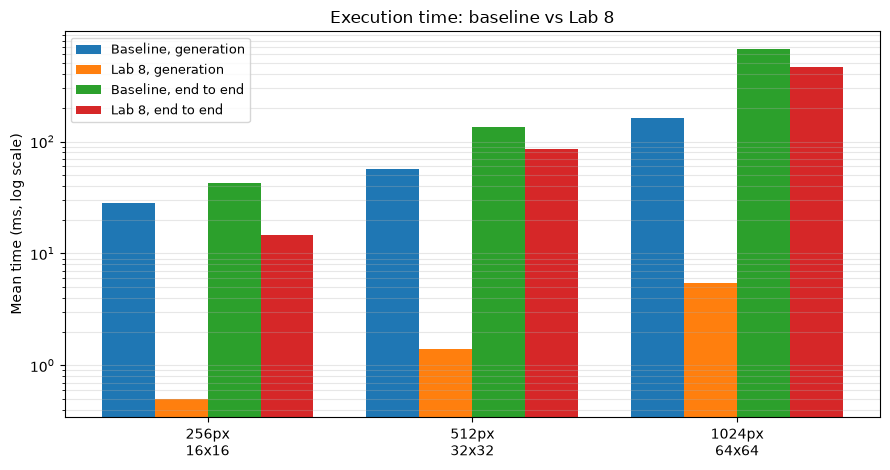

Saved /Users/megukanzawa/Downloads/CS/Northeastern/CS5130/Labs/Week2/perf_results/comparison_speedup.png


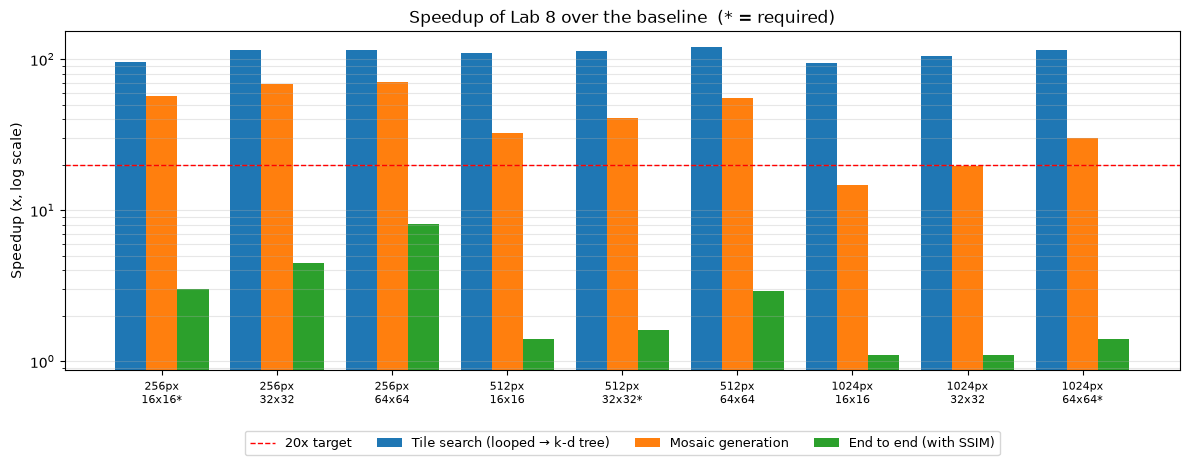

Saved /Users/megukanzawa/Downloads/CS/Northeastern/CS5130/Labs/Week2/perf_results/comparison_scaling.png


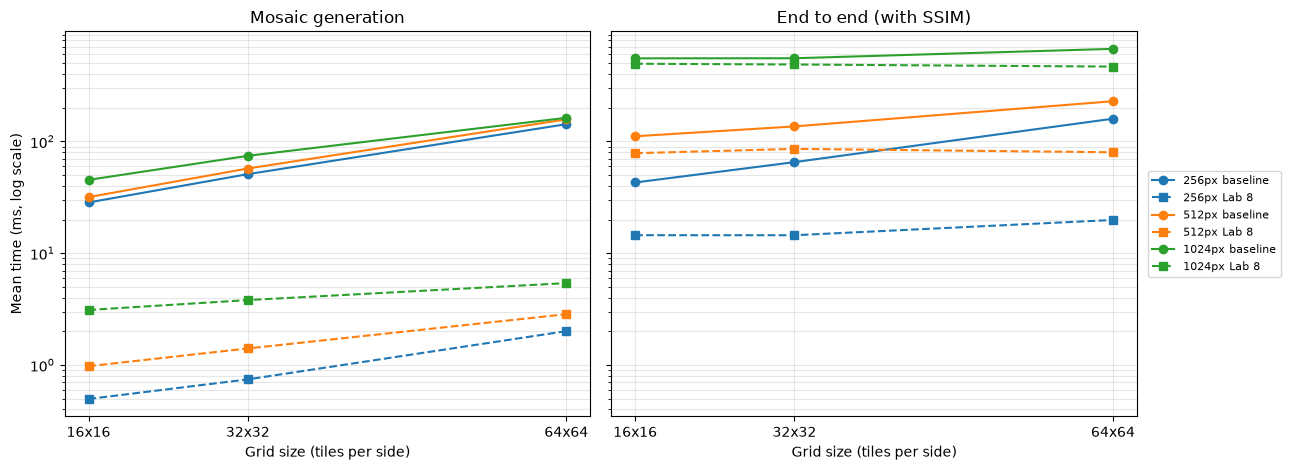

In [45]:
def plot_comparison(rows, search_rows):
    req = [r for r in rows if r["required"]]
    labels = [f"{r['image_size']}px\n{r['grid_size']}x{r['grid_size']}" for r in req]
    x = np.arange(len(req))

    # 1. Execution time, required configurations
    fig, ax = plt.subplots(figsize=(9, 4.8))
    bars = [("Baseline, generation", "baseline_gen_ms"), ("Lab 8, generation", "lab8_gen_ms"),
            ("Baseline, end to end", "baseline_full_ms"), ("Lab 8, end to end", "lab8_full_ms")]
    width = 0.2
    for i, (label, key) in enumerate(bars):
        ax.bar(x + (i - 1.5) * width, [r[key] for r in req], width, label=label)
    ax.set_xticks(x, labels)
    ax.set_yscale("log")
    ax.set_ylabel("Mean time (ms, log scale)")
    ax.set_title("Execution time: baseline vs Lab 8")
    ax.grid(True, axis="y", which="both", alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    save_and_show(fig, "comparison_times.png")

    # 2. Speedup factors, all configurations
    fig, ax = plt.subplots(figsize=(12, 4.8))
    all_labels = [f"{r['image_size']}px\n{r['grid_size']}x{r['grid_size']}" + ("*" if r["required"] else "")
                  for r in rows]
    xa = np.arange(len(rows))
    ax.bar(xa - 0.27, [r["search_speedup"] for r in search_rows], 0.27, label="Tile search (looped → k-d tree)")
    ax.bar(xa, [r["gen_speedup"] for r in rows], 0.27, label="Mosaic generation")
    ax.bar(xa + 0.27, [r["full_speedup"] for r in rows], 0.27, label="End to end (with SSIM)")
    ax.axhline(20, color="red", linestyle="--", linewidth=1, label="20x target")
    ax.set_xticks(xa, all_labels, fontsize=8)
    ax.set_yscale("log")
    ax.set_ylabel("Speedup (x, log scale)")
    ax.set_title("Speedup of Lab 8 over the baseline  (* = required)")
    ax.grid(True, axis="y", which="both", alpha=0.3)
    ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
    fig.tight_layout()
    save_and_show(fig, "comparison_speedup.png")

    # 3. Scaling with image and grid size
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
    for ax, (title, base_key, opt_key) in zip(axes, [
            ("Mosaic generation", "baseline_gen_ms", "lab8_gen_ms"),
            ("End to end (with SSIM)", "baseline_full_ms", "lab8_full_ms")]):
        for size, color in zip(IMAGE_SIZES, plt.get_cmap("tab10").colors):
            r = [row for row in rows if row["image_size"] == size]
            grids = [row["grid_size"] for row in r]
            ax.plot(grids, [row[base_key] for row in r], "o-", color=color, label=f"{size}px baseline")
            ax.plot(grids, [row[opt_key] for row in r], "s--", color=color, label=f"{size}px Lab 8")
        ax.set_title(title)
        ax.set_xlabel("Grid size (tiles per side)")
        ax.set_xticks(GRID_SIZES, [f"{g}x{g}" for g in GRID_SIZES])
        ax.set_yscale("log")
        ax.grid(True, which="both", alpha=0.3)
    axes[0].set_ylabel("Mean time (ms, log scale)")
    axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.tight_layout()
    save_and_show(fig, "comparison_scaling.png")


plot_comparison(comparison_rows, search_rows)

### 5f. Target check and tables for the report

In [46]:
def report_tables(rows, search_rows):
    key = (512, 32)
    target = next(r for r in rows if (r["image_size"], r["grid_size"]) == key)
    search = next(r for r in search_rows if (r["image_size"], r["grid_size"]) == key)
    meets = lambda x: "meets" if x >= 20 else "below"
    lines = [
        "## Target check (512x512 image, 32x32 grid, target >= 20x)",
        "",
        f"- Tile search, find_best_tile_looped -> k-d tree: {search['looped_ms']:.3f} ms -> "
        f"{search['kdtree_ms']:.3f} ms, **{search['search_speedup']:.1f}x** ({meets(search['search_speedup'])} the target)",
        f"- Mosaic generation: {target['baseline_gen_ms']:.2f} ms -> {target['lab8_gen_ms']:.2f} ms, "
        f"**{target['gen_speedup']:.1f}x** ({meets(target['gen_speedup'])} the target)",
        f"- End to end with MSE and SSIM: {target['baseline_full_ms']:.2f} ms -> {target['lab8_full_ms']:.2f} ms, "
        f"**{target['full_speedup']:.1f}x** ({meets(target['full_speedup'])} the target)",
        "",
    ]
    tables = [
        ("Tile search: find_best_tile_looped vs k-d tree", search_rows, "looped_ms", "kdtree_ms", "search_speedup"),
        ("Mosaic generation (metrics off in both)", rows, "baseline_gen_ms", "lab8_gen_ms", "gen_speedup"),
        ("End to end (including MSE and SSIM)", rows, "baseline_full_ms", "lab8_full_ms", "full_speedup"),
    ]
    for title, data, base_key, opt_key, sp_key in tables:
        lines += [f"### {title}", "",
                  "| IMAGE SIZE | GRID SIZE | BASELINE TIME (s) | LAB 8 TIME (s) | SPEEDUP |",
                  "| --- | --- | --- | --- | --- |"]
        for r in data:
            if r["required"]:
                lines.append(f"| {r['image_size']} x {r['image_size']} | {r['grid_size']} x {r['grid_size']} "
                             f"| {r[base_key] / 1000:.6f} | {r[opt_key] / 1000:.6f} | {r[sp_key]:.1f}x |")
        lines.append("")
    worst = min(min(r["same_tiles_pct"] for r in rows), min(r["same_tiles_pct"] for r in search_rows))
    largest_mse = max(r["mosaic_mse"] for r in rows)
    lines += ["### Correctness check", "",
              f"- Cells assigned the same tile as the baseline: {worst:.2f}% (lowest across all 9 configurations)",
              f"- MSE between baseline and Lab 8 mosaics: {largest_mse:.4f} (largest across all 9 configurations)"]
    text = "\n".join(lines)
    print(text)
    print(f"\nSaved {save_text('report_tables.md', text)}")


report_tables(comparison_rows, search_rows)

## Target check (512x512 image, 32x32 grid, target >= 20x)

- Tile search, find_best_tile_looped -> k-d tree: 33.558 ms -> 0.296 ms, **113.4x** (meets the target)
- Mosaic generation: 57.24 ms -> 1.41 ms, **40.8x** (meets the target)
- End to end with MSE and SSIM: 136.22 ms -> 85.76 ms, **1.6x** (below the target)

### Tile search: find_best_tile_looped vs k-d tree

| IMAGE SIZE | GRID SIZE | BASELINE TIME (s) | LAB 8 TIME (s) | SPEEDUP |
| --- | --- | --- | --- | --- |
| 256 x 256 | 16 x 16 | 0.008248 | 0.000086 | 96.4x |
| 512 x 512 | 32 x 32 | 0.033558 | 0.000296 | 113.4x |
| 1024 x 1024 | 64 x 64 | 0.124280 | 0.001074 | 115.8x |

### Mosaic generation (metrics off in both)

| IMAGE SIZE | GRID SIZE | BASELINE TIME (s) | LAB 8 TIME (s) | SPEEDUP |
| --- | --- | --- | --- | --- |
| 256 x 256 | 16 x 16 | 0.028430 | 0.000496 | 57.4x |
| 512 x 512 | 32 x 32 | 0.057245 | 0.001405 | 40.8x |
| 1024 x 1024 | 64 x 64 | 0.162716 | 0.005397 | 30.2x |

### End to end (including MSE and SSIM)



### 5g. Profile again: cProfile of the optimized version

Function-level profile of `lab8.mosaic_construction` for the required configurations, to confirm where the remaining time goes.

In [47]:
def profile_lab8(images, configs, top):
    print(banner("PART 5g: cProfile of lab8.mosaic_construction"))
    for size, grid in configs:
        tile = tile_size_for(size, grid)
        lab8.mosaic_construction(images[size], tile)   # warm the resize cache first
        profiler = cProfile.Profile()
        profiler.runcall(lab8.mosaic_construction, images[size], tile)

        stem = f"cprofile_lab8_{size}px_grid{grid}"
        profiler.dump_stats(RESULTS_DIR / f"{stem}.prof")
        buf = io.StringIO()
        stats = pstats.Stats(profiler, stream=buf).strip_dirs()
        buf.write(f"\n### lab8: {size}x{size} image, {grid}x{grid} grid ({tile} px tiles)\n")
        buf.write("\n--- sorted by cumulative time ---\n")
        stats.sort_stats("cumulative").print_stats(top)
        buf.write("\n--- sorted by internal time ---\n")
        stats.sort_stats("tottime").print_stats(top)
        text = buf.getvalue()
        print(text)
        print(f"Saved {save_text(stem + '.txt', text)} and {stem}.prof")


profile_lab8(images, REQUIRED_CONFIGS, CPROFILE_TOP)


PART 5g: cProfile of lab8.mosaic_construction

### lab8: 256x256 image, 16x16 grid (16 px tiles)

--- sorted by cumulative time ---
         1151 function calls (1147 primitive calls) in 0.014 seconds

   Ordered by: cumulative time
   List reduced from 125 to 20 due to restriction <20>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.014    0.014 lab8.py:329(mosaic_construction)
        1    0.000    0.000    0.014    0.014 lab8.py:254(build_mosaic)
        1    0.000    0.000    0.013    0.013 lab8.py:143(calculate_ssim)
      4/1    0.001    0.000    0.013    0.013 _structural_similarity.py:15(structural_similarity)
       15    0.000    0.000    0.012    0.001 _filters.py:1552(uniform_filter)
       30    0.000    0.000    0.011    0.000 _filters.py:1501(uniform_filter1d)
       30    0.011    0.000    0.011    0.000 {built-in method scipy.ndimage._nd_image.uniform_filter1d}
       45    0.000    0.000    0.000    0.000 _ni_

## Saved files

In [48]:
for path in sorted(RESULTS_DIR.iterdir()):
    print(f"{path.name:<40} {path.stat().st_size / 1024:>8.1f} KB")

baseline_breakdown.csv                        1.3 KB
baseline_breakdown.png                       84.8 KB
baseline_breakdown.txt                        1.6 KB
baseline_scaling.png                         84.1 KB
baseline_timing.csv                           0.8 KB
baseline_timing.txt                           1.1 KB
comparison_scaling.png                       96.7 KB
comparison_speedup.png                       50.8 KB
comparison_tile_search.csv                    0.7 KB
comparison_tile_search.txt                    1.4 KB
comparison_times.png                         42.1 KB
comparison_timing.csv                         1.0 KB
comparison_timing.txt                         1.5 KB
cprofile_1024px_grid64.prof                  29.6 KB
cprofile_1024px_grid64.txt                    5.7 KB
cprofile_256px_grid16.prof                   29.2 KB
cprofile_256px_grid16.txt                     5.6 KB
cprofile_512px_grid32.prof                   29.5 KB
cprofile_512px_grid32.txt                     